# F4_02 · Notebook final: flujo completo F1 → F4

**Objetivo:** Reunir en un solo notebook, ordenado por fase, el flujo completo del proyecto: desde la definición del problema hasta las visualizaciones, ejecutable de principio a fin con *Restart Kernel and Run All*.

**Pregunta:** ¿qué proporción de los egresos hospitalarios por colelitiasis registró una colecistectomía como intervención principal en Cautín y Malleco durante 2022, y cómo varió entre los grupos de riesgo, sus grupos de referencia y ambas provincias?

| Fase | Qué se hace aquí | Notebook de detalle |
|---|---|---|
| F1 | Entorno reproducible y definición del problema | `F1/F1_01_definicion.ipynb` |
| F2 | Datos de La Araucanía y transformación | `F2/F2_01` a `F2/F2_04` |
| F3 | Núcleo orientado a objetos, pruebas y proporciones | `F3/F3_01`, `F3/F3_02` |
| F4 | Visualizaciones analíticas | `F4/F4_01_visualizaciones.ipynb` |

Este notebook parte del subconjunto regional ya versionado (`data/processed/egresos_araucania_2022.csv`), por lo que no necesita la base nacional de 341 MB.

## F1 · Entorno y definición

Se ubica la raíz del repositorio con el mismo bloque que usan todos los notebooks y se verifica que el entorno tenga las versiones fijadas en `requirements.txt`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

# Raíz del repositorio: funciona si el notebook se abre desde su carpeta (F1, F2...) o desde la raíz
RAIZ = Path.cwd()
RAIZ = RAIZ.parent if RAIZ.name.startswith("F") else RAIZ
sys.path.insert(0, str(RAIZ))

from src.entorno import verificar_entorno
from src.pipeline import Pipeline
from src.etapas import (
    FiltroColelitiasis,
    AsignadorProvincia,
    MarcadorGruposRiesgo,
    MarcadorColecistectomia,
)
from src.proporciones import CalcNumpy

versiones = verificar_entorno()

Versión de Python: 3.13.18
Entorno virtual del proyecto (.venv): True
pandas: 3.1.1
numpy: 2.5.4
matplotlib: 3.11.2
seaborn: 0.13.2


**Definiciones operacionales** (detalle en F1_01):
- **Unidad de análisis:** el egreso hospitalario, no la persona.
- **Colelitiasis:** diagnóstico principal CIE-10 K80.0–K80.8.
- **Provincia:** comuna de residencia 091 = Cautín y 092 = Malleco.
- **Grupos de riesgo (por separado):** mujeres, personas que se identifican con una etnia y tramo de 40 a 49 años, cada uno frente a su grupo de referencia.
- **Colecistectomía:** la glosa de la intervención principal corresponde a una colecistectomía; vacía = sin colecistectomía registrada.

## F2 · Datos de partida

En F2_01 se filtraron los egresos de residentes de La Araucanía desde la base nacional del DEIS 2022 y se guardó el subconjunto. Aquí se carga ese archivo, leyendo todo como texto para conservar los ceros iniciales de los códigos.

In [2]:
ENTRADA = RAIZ / "data" / "processed" / "egresos_araucania_2022.csv"
araucania = pd.read_csv(ENTRADA, dtype=str)

print("Egresos de La Araucanía:", araucania.shape[0], "| columnas:", araucania.shape[1])

Egresos de La Araucanía: 84618 | columnas: 18


## F3 · Núcleo orientado a objetos

La transformación de F2 se ejecuta con las clases de F3. El marcador de colecistectomía **primero se ajusta** con los egresos por colelitiasis (aprende qué glosas corresponden a colecistectomía) y **después se aplica** dentro del Pipeline.

In [3]:
# 1) Ajustar: el marcador aprende el vocabulario de glosas a partir de los egresos K80
k80 = FiltroColelitiasis().ejecutar(araucania)
marcador = MarcadorColecistectomia().ajustar(k80)
print("Glosas aprendidas como colecistectomía:")
for glosa in sorted(marcador.vocabulario):
    print("  -", glosa)

# 2) Aplicar: el Pipeline ejecuta las cuatro etapas en orden, con el marcador ya ajustado
flujo = Pipeline([
    FiltroColelitiasis(),
    AsignadorProvincia(),
    MarcadorGruposRiesgo(),
    marcador,
])
resultado = flujo.ejecutar(araucania)
print()
print("Egresos por colelitiasis:", len(resultado), "| columnas:", resultado.shape[1])

Glosas aprendidas como colecistectomía:
  - Colecistectomía c/s colangiografía operatoria
  - Colecistectomía por videolaparoscopía, proc. completo
  - Colecistectomía y coledocostomía (sonda T y colangiografía postoperatoria) c/s colangiografía operatoria

Egresos por colelitiasis: 3789 | columnas: 23


### Verificación

El resultado debe coincidir con el archivo generado en F2_03, y las 20 pruebas automatizadas del proyecto deben pasar.

In [4]:
CSV_F2 = RAIZ / "data" / "processed" / "egresos_araucania_k80_transformado.csv"
csv_f2 = pd.read_csv(CSV_F2, dtype=str)
derivadas = ["PROVINCIA_RESIDENCIA", "GRUPO_RIESGO_MUJER", "GRUPO_RIESGO_ETNIA",
             "GRUPO_RIESGO_40_49", "FLAG_COLECISTECTOMIA"]
comparable = resultado[derivadas].astype(str).reset_index(drop=True)
assert len(resultado) == len(csv_f2) == 3789
assert (comparable.values == csv_f2[derivadas].values).all()
print("OK  3.789 egresos y 5 columnas derivadas idénticas al CSV de F2_03")

OK  3.789 egresos y 5 columnas derivadas idénticas al CSV de F2_03


In [5]:
import unittest

pruebas = unittest.defaultTestLoader.discover(str(RAIZ / "tests"))
informe = unittest.TextTestRunner(verbosity=1).run(pruebas)
print("Pruebas ejecutadas:", informe.testsRun, "| todas correctas:", informe.wasSuccessful())

....................
----------------------------------------------------------------------
Ran 20 tests in 0.016s

OK


Pruebas ejecutadas: 20 | todas correctas: True


### Proporciones con intervalo de Wilson al 95 %

Se usa `CalcNumpy`, la estrategia elegida en F3_02 por ser la más rápida.

In [6]:
NOMBRES_GRUPO = {
    "GRUPO_RIESGO_MUJER": "Mujeres",
    "GRUPO_RIESGO_ETNIA": "Pertenencia a etnia",
    "GRUPO_RIESGO_40_49": "40 a 49 años",
}
calculador = CalcNumpy(resultado)
tabla = calculador.calcular()
tabla["grupo"] = tabla["grupo"].map(NOMBRES_GRUPO)
for col in ["proporcion", "ic95_inf", "ic95_sup"]:
    tabla[col + "_%"] = (tabla[col] * 100).round(1)

assert round(calculador.proporcion_global() * 100, 1) == 80.7, "Cambió la proporción global"
print(f"Proporción global con colecistectomía: {calculador.proporcion_global() * 100:.1f} %")
tabla[["grupo", "provincia", "en_grupo", "egresos", "con_colecistectomia",
       "proporcion_%", "ic95_inf_%", "ic95_sup_%"]]

Proporción global con colecistectomía: 80.7 %


,grupo,provincia,en_grupo,egresos,con_colecistectomia,proporcion_%,ic95_inf_%,ic95_sup_%
0,40 a 49 años,Cautín,False,2496,2001,80.2,78.6,81.7
1,40 a 49 años,Cautín,True,521,465,89.3,86.3,91.6
2,40 a 49 años,Malleco,False,645,490,76.0,72.5,79.1
3,40 a 49 años,Malleco,True,127,100,78.7,70.8,85.0
4,Pertenencia a etnia,Cautín,False,2384,1967,82.5,80.9,84.0
5,Pertenencia a etnia,Cautín,True,633,499,78.8,75.5,81.8
6,Pertenencia a etnia,Malleco,False,652,505,77.5,74.1,80.5
7,Pertenencia a etnia,Malleco,True,120,85,70.8,62.2,78.2
8,Mujeres,Cautín,False,806,622,77.2,74.1,79.9
9,Mujeres,Cautín,True,2211,1844,83.4,81.8,84.9


## F4 · Visualizaciones

Las figuras se construyen en `F4/F4_01_visualizaciones.ipynb` y se guardan en `F4/figuras/`. Aquí se muestran en orden.

Figura 1 · Proporción por grupo de riesgo y provincia, con IC 95 %


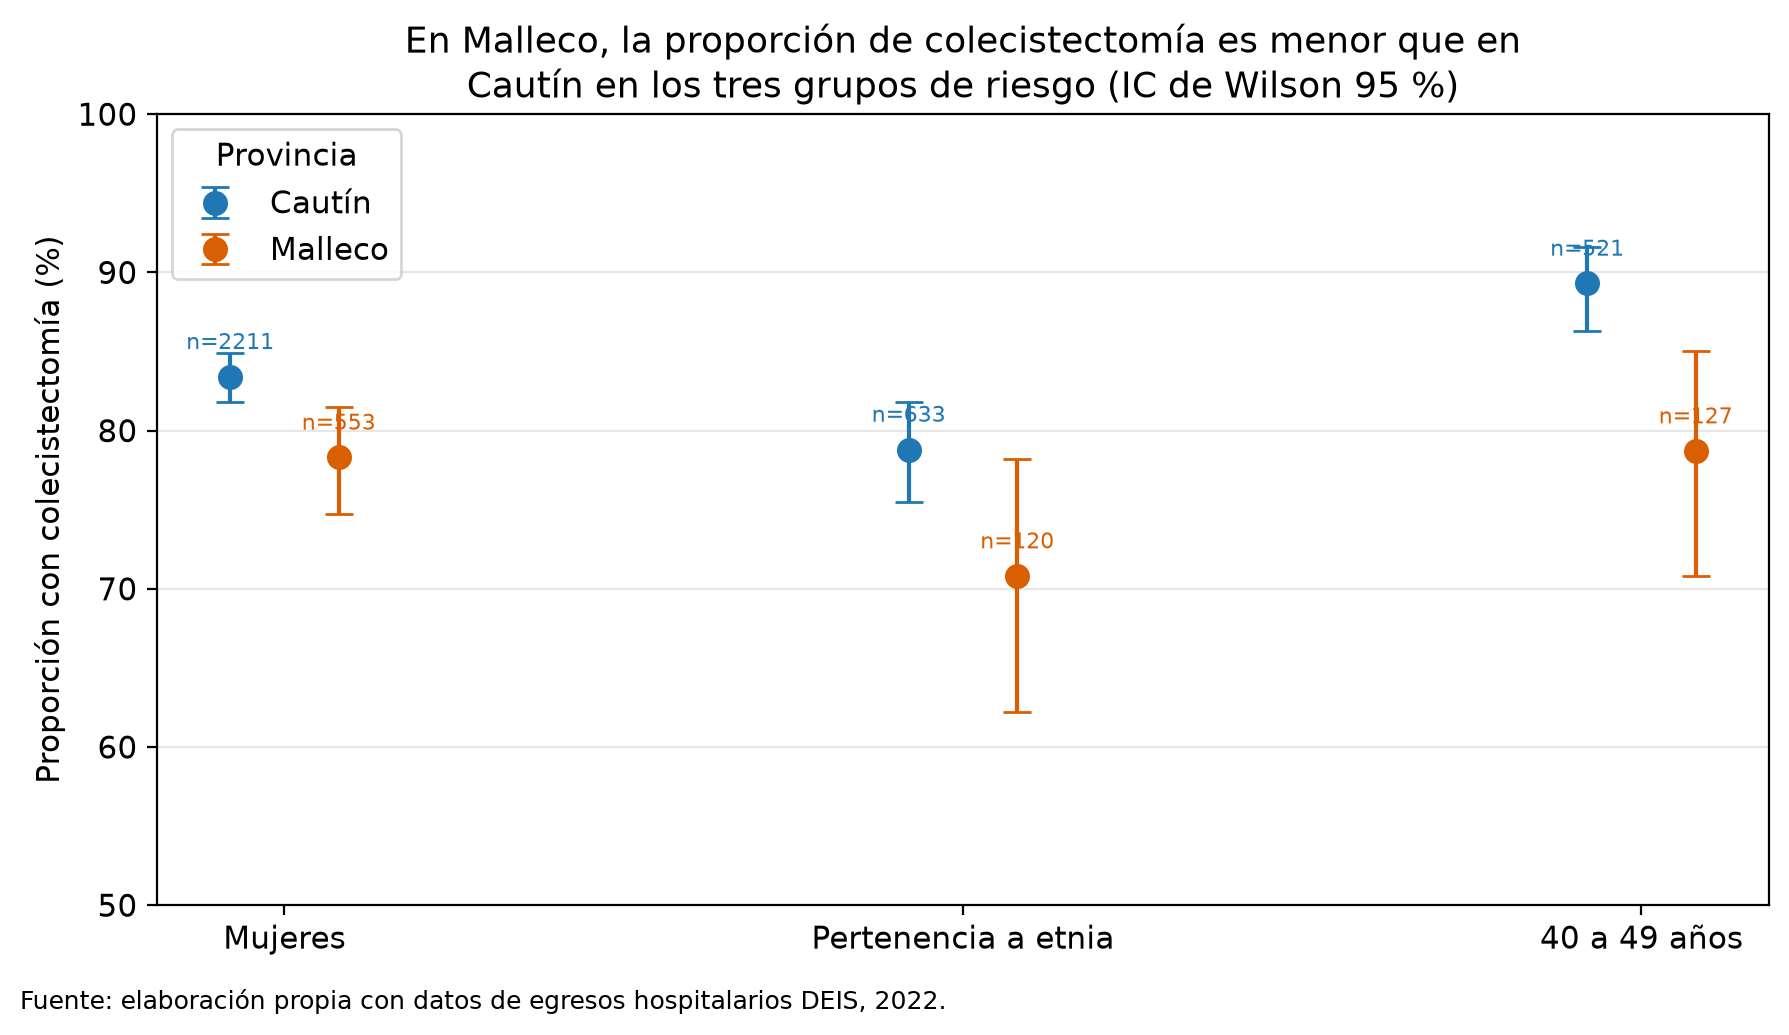

Figura 2 · Cada grupo de riesgo frente a su grupo de referencia


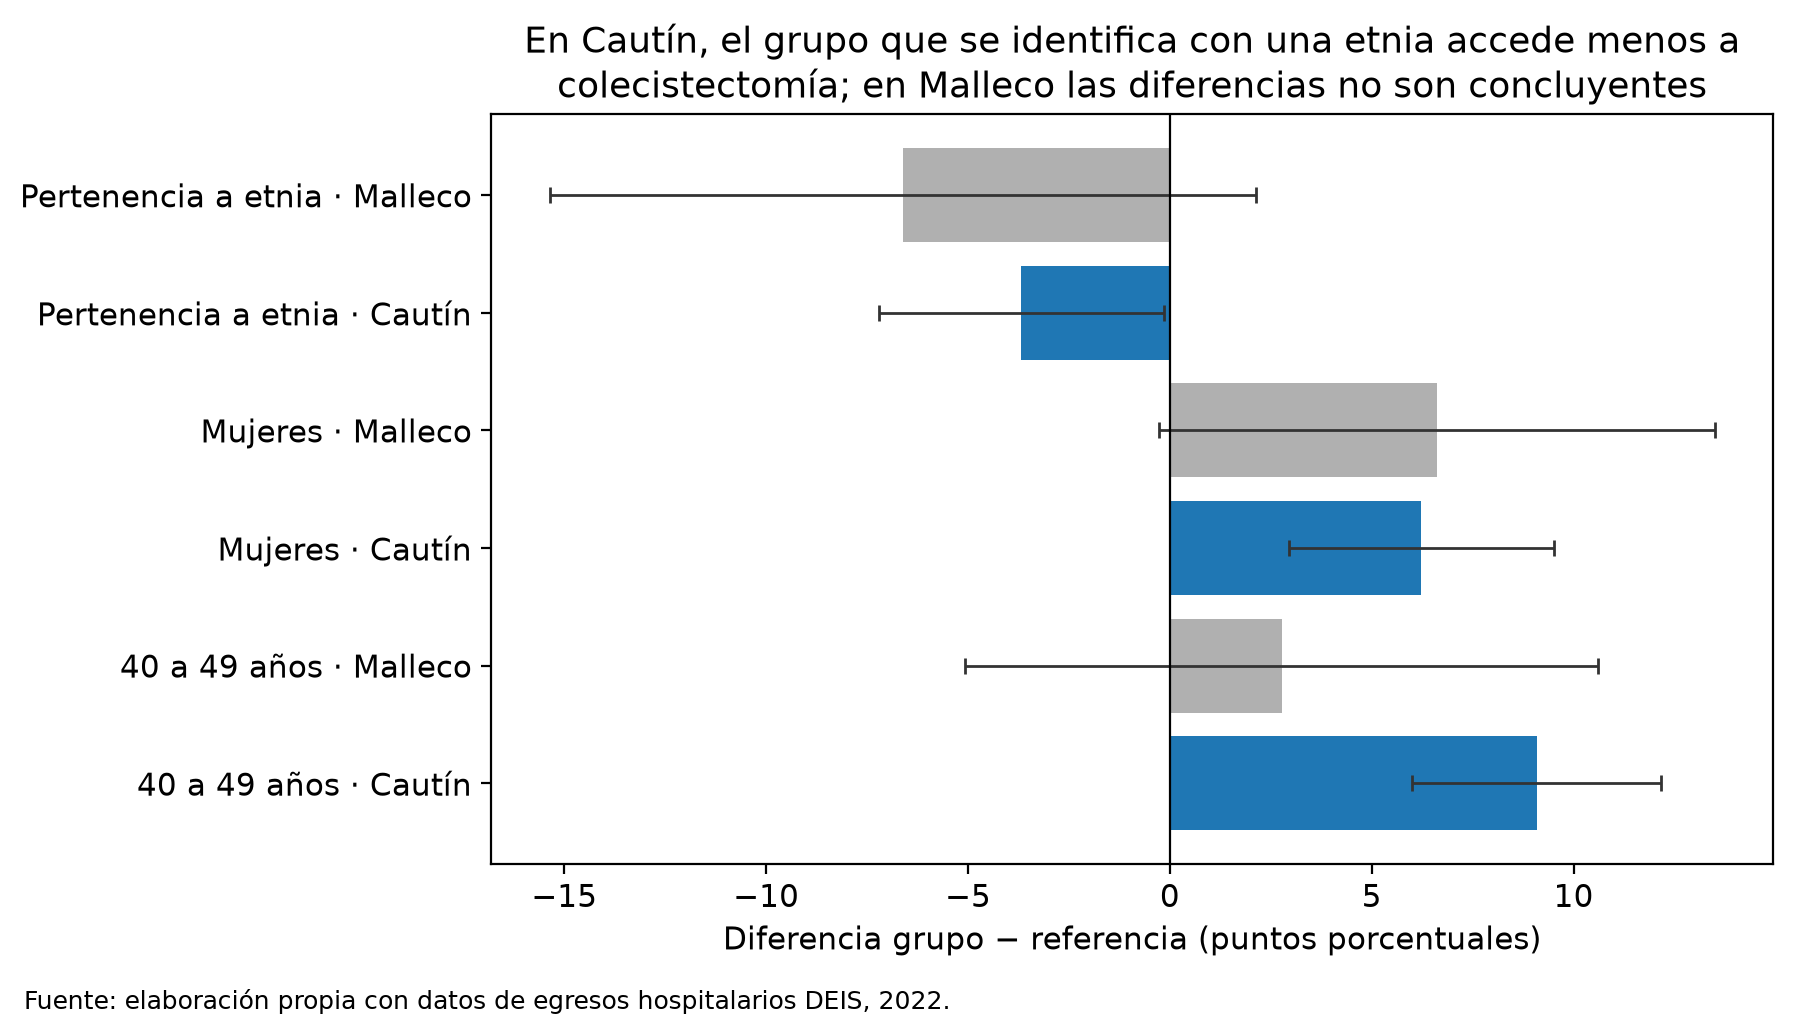

Figura 3 · Egresos sin colecistectomía por grupo y provincia


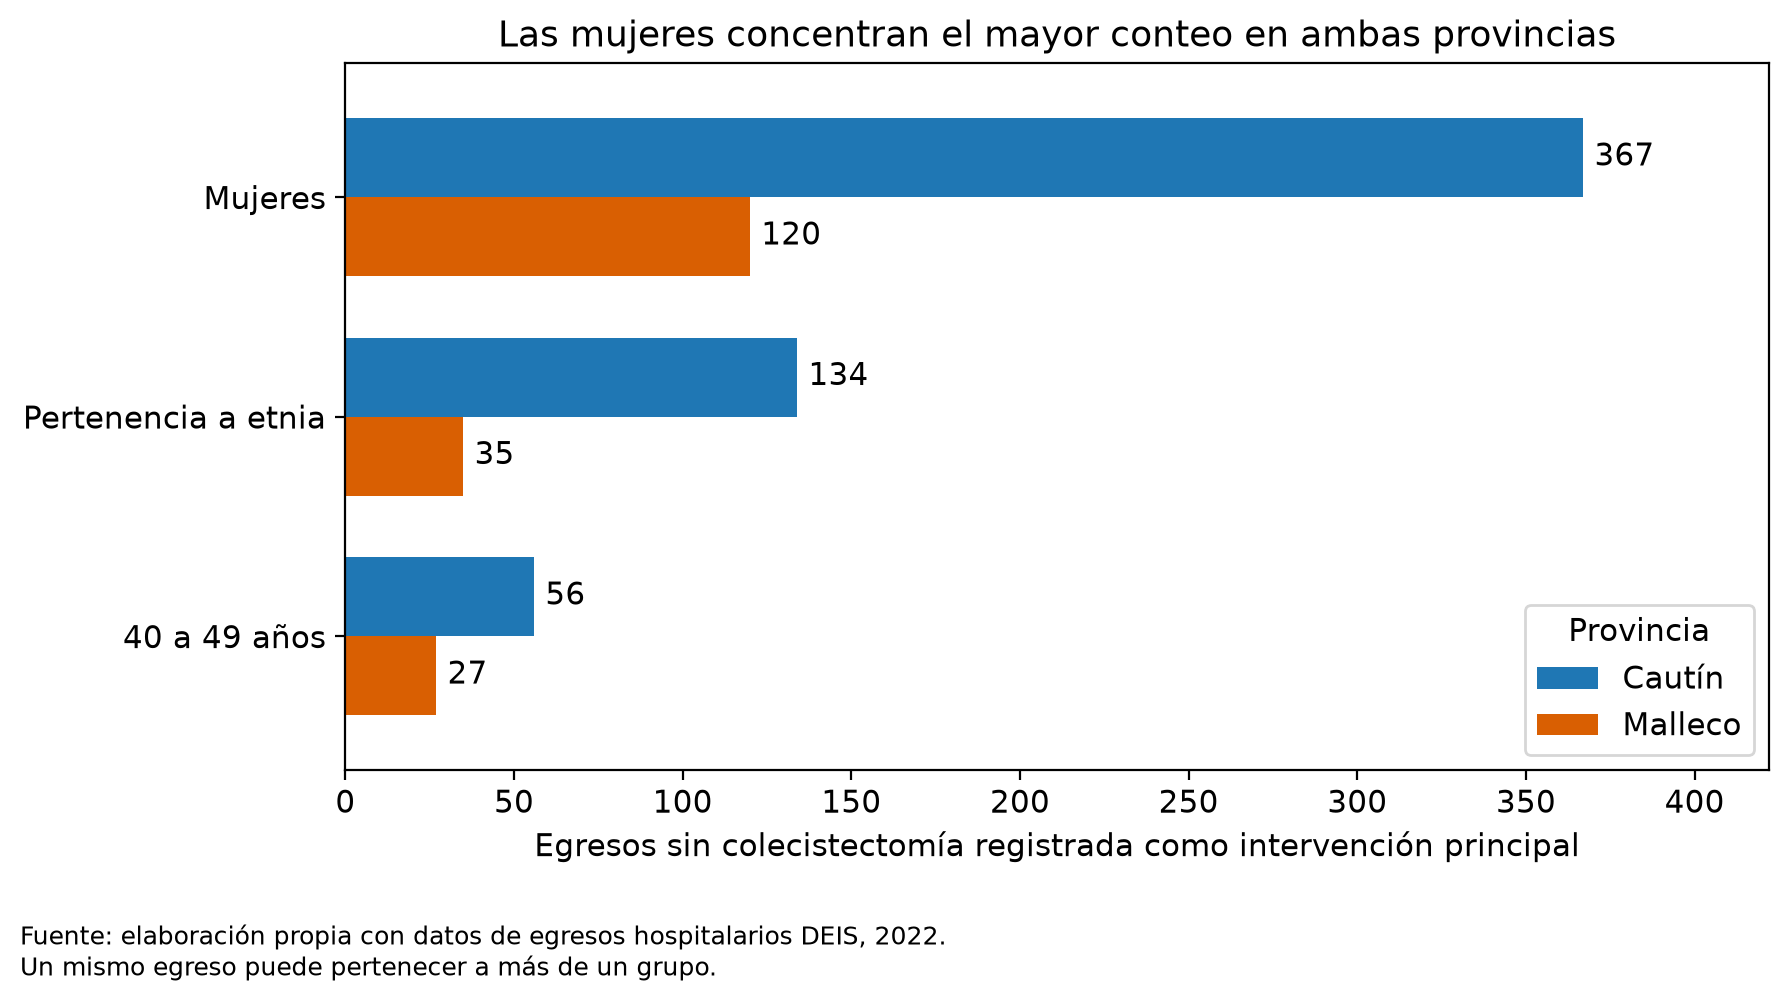

In [7]:
FIGURAS = {
    "figura1": "Figura 1 · Proporción por grupo de riesgo y provincia, con IC 95 %",
    "figura2": "Figura 2 · Cada grupo de riesgo frente a su grupo de referencia",
    "figura3": "Figura 3 · Egresos sin colecistectomía por grupo y provincia",
}
for nombre, titulo in FIGURAS.items():
    ruta = RAIZ / "F4" / "figuras" / f"{nombre}.png"
    print(titulo)
    if ruta.exists():
        display(Image(filename=str(ruta)))
    else:
        print("  (pendiente: ejecutar F4_01 y subir", ruta.name, "a F4/figuras/)")

## Cierre

_El flujo completo de las cuatro fases se ejecuta de principio a fin y entrega el mismo resultado validado antes: 3.789 egresos por colelitiasis en La Araucanía durante 2022, de los cuales un 80,7 % registró colecistectomía como intervención principal, con una proporción sistemáticamente menor en Malleco que en Cautín en los tres grupos de riesgo. El hallazgo central surge al comparar cada grupo con su referencia: en Cautín, las mujeres y el grupo de 40 a 49 años acceden significativamente más a la cirugía, mientras que quienes se identifican con una etnia acceden menos (−3,7 puntos porcentuales), una brecha que apunta en sentido contrario al resto. En Malleco, ninguna diferencia resulta concluyente por los tamaños muestrales reducidos. Las cifras de este notebook coinciden con las del informe y las de la presentación audiovisual._

**Qué se comprobó en este notebook:** el flujo completo corre de principio a fin; el resultado coincide con el archivo de F2_03 (3.789 egresos); las pruebas automatizadas pasan; y las proporciones son las mismas que se reportan en el informe y en el video.